# Retail / E-commerce Data Analyst Capstone
## Sales performance and customer insights
**Business question:** How is the store performing, and what drives revenue?
    
The notebook loads all seven CSVs, documents cleaning, validates joins, builds a line-level fact table, calculates KPIs and exports ten JPG charts. The Streamlit dashboard uses the same metrics and chart functions.

In [1]:
from IPython.display import Image, display
import matplotlib.pyplot as plt
import pandas as pd
from analysis_pipeline import CHARTS, ROOT, analyze, build_fact, clean_tables, export_cleaned, make_chart

source = ROOT / "data" / "raw_datasets"
tables, audit = clean_tables(source)
display(pd.DataFrame({"raw_rows": {name: len(pd.read_csv(source / f"{name}.csv")) for name in tables},
                      "clean_rows": {name: len(frame) for name, frame in tables.items()}}))

,raw_rows,clean_rows
customers,5050,5000
products,800,800
orders,15075,15000
order_items,37763,37501
shipments,15000,15000
payments,15000,15000
returns,1200,1200


## 1. Cleaning rules
- Trim text and drop rows identical across every source column after trimming. Each table must have a unique nonblank primary ID. A conflicting duplicate ID stops the pipeline for review.
- Normalize category aliases to eight standard categories and convert pc/pcs to piece. Parse mixed dates with month-first conventions for slash-formatted source dates. Strip the peso sign and thousands separators from monetary strings before numeric conversion.
- Fill missing gender, loyalty tier, geography labels and refund flags with Unknown. Leave missing demographic, contact, inventory, shipping, payment and most refund values blank. Set blank refund amounts to zero only when the refund flag explicitly says No.
- Assume zero discount when a discount is missing or outside 0–100%. Keep original purchase prices and add an analysis price that falls back to catalog price. If both prices are unavailable, exclude that line from revenue. Flag zero, negative and missing quantities and exclude them from revenue.
- Validate the six parent-child relationships. Keep unmatched rows and flag the missing references. In the fact table, unmatched dimensions contribute to Unknown buckets when a line has a usable price. The product ranking uses matched catalog products only.
- Retain payments, shipments and returns as cleaned standalone tables. Their dates and statuses are not used to infer revenue or cancellation dates.

In [2]:
display(audit.loc[audit["rows"].gt(0)].reset_index(drop=True))
audit.to_csv(ROOT / "data_quality_audit.csv", index=False)

,table,check,rows
0,customers,Exact duplicate rows removed,50
1,orders,Exact duplicate rows removed,75
2,order_items,Exact duplicate rows removed,262
3,returns,Blank refund amounts set to zero for explicit No,53
4,orders,Missing or invalid discounts assumed zero,756
5,orders,Unmatched customer_id retained and flagged,43
6,order_items,Unmatched product_id retained and flagged,129
7,order_items,Price source · Catalog estimate,2227
8,order_items,Price source · Missing,9
9,order_items,Nonpositive or missing quantities retained and...,372


## 2. Build and validate the sales fact
**Grain:** One row per order item. Start with cleaned items and left-join orders, products and customers. Each join is many-to-one and must preserve line count.
    
**Revenue:** Quantity × analysis unit price × (1 − discount), rounded to cents per line for Completed and Shipped orders. Shipping fees, payment amounts and refund amounts are outside this merchandise sales estimate. AOV uses orders with at least one priced line, so a partially priced order can contribute a partial value. Total order counts for cancellation reporting use all statuses.
    
**Customer type:** The first Completed or Shipped order observed for a matched customer is New. Later eligible orders are Repeat. This classification is set before filtering. This is an observed history measure and does not identify purchases made before the dataset began.

In [3]:
fact, orders = build_fact(tables)
tables["orders"] = orders
export_cleaned(tables, fact, ROOT / "data" / "cleaned_datasets")
assert fact["order_item_id"].is_unique
assert len(fact) == len(tables["order_items"])
assert len(pd.read_csv(ROOT / "data" / "cleaned_datasets" / "sales_fact.csv")) == len(fact)
display(fact[["order_item_id", "order_id", "category", "region_name", "price_source", "line_revenue"]].head(8))

,order_item_id,order_id,category,region_name,price_source,line_revenue
0,ITEM000000001,ORD0000001,Sports,Northern Mindanao,Purchase price,<NA>
1,ITEM000000002,ORD0000002,Beauty,Central Visayas,Purchase price,156.63
2,ITEM000000003,ORD0000002,Electronics,Central Visayas,Purchase price,88.0
3,ITEM000000004,ORD0000002,Groceries,Central Visayas,Purchase price,94.25
4,ITEM000000005,ORD0000002,Home & Kitchen,Central Visayas,Purchase price,102.3
5,ITEM000000006,ORD0000002,Toys,Central Visayas,Purchase price,101.96
6,ITEM000000007,ORD0000003,Electronics,Metro Manila,Purchase price,148.33
7,ITEM000000008,ORD0000003,Books,Metro Manila,Purchase price,101.08


## 3. Sales and customer KPIs

In [4]:
months = orders["order_datetime"].dt.to_period("M")
metrics = analyze(fact, orders, str(months.min()), str(months.max()))
display(pd.Series({
    "Estimated merchandise revenue (PHP)": f"{metrics['revenue']:,.2f}",
    "Revenue-bearing orders": f"{metrics['order_count']:,}",
    "All orders": f"{len(orders):,}",
    "Average order value (PHP)": f"{metrics['aov']:,.2f}",
    "Cancellation rate": f"{orders.order_status.eq('Cancelled').mean():.2%}",
}, name="Full period").to_frame())
display(metrics["order_mix"])
display(metrics["customer_counts"].rename("Distinct matched customers").to_frame())
for key in ["monthly", "categories", "regions", "channels", "customer_types", "cities"]:
    assert abs(metrics[key].sum() - metrics["revenue"]) < 0.01
assert metrics["order_mix"]["orders"].sum() == metrics["order_count"]

,Full period
Estimated merchandise revenue (PHP),"5,325,284.86"
Revenue-bearing orders,"11,643"
All orders,"15,000"
Average order value (PHP),457.38
Cancellation rate,8.23%


,revenue,orders
customer_type,,
Repeat,3250550.47,7095
New,2059958.58,4515
Unknown,14775.81,33


,Distinct matched customers
customer_type,
New,1134
Repeat,3386


## 4. Create and export ten charts
The cancellation trend is the share of orders placed in each month with a current status of Cancelled. The source does not contain a cancellation event timestamp.

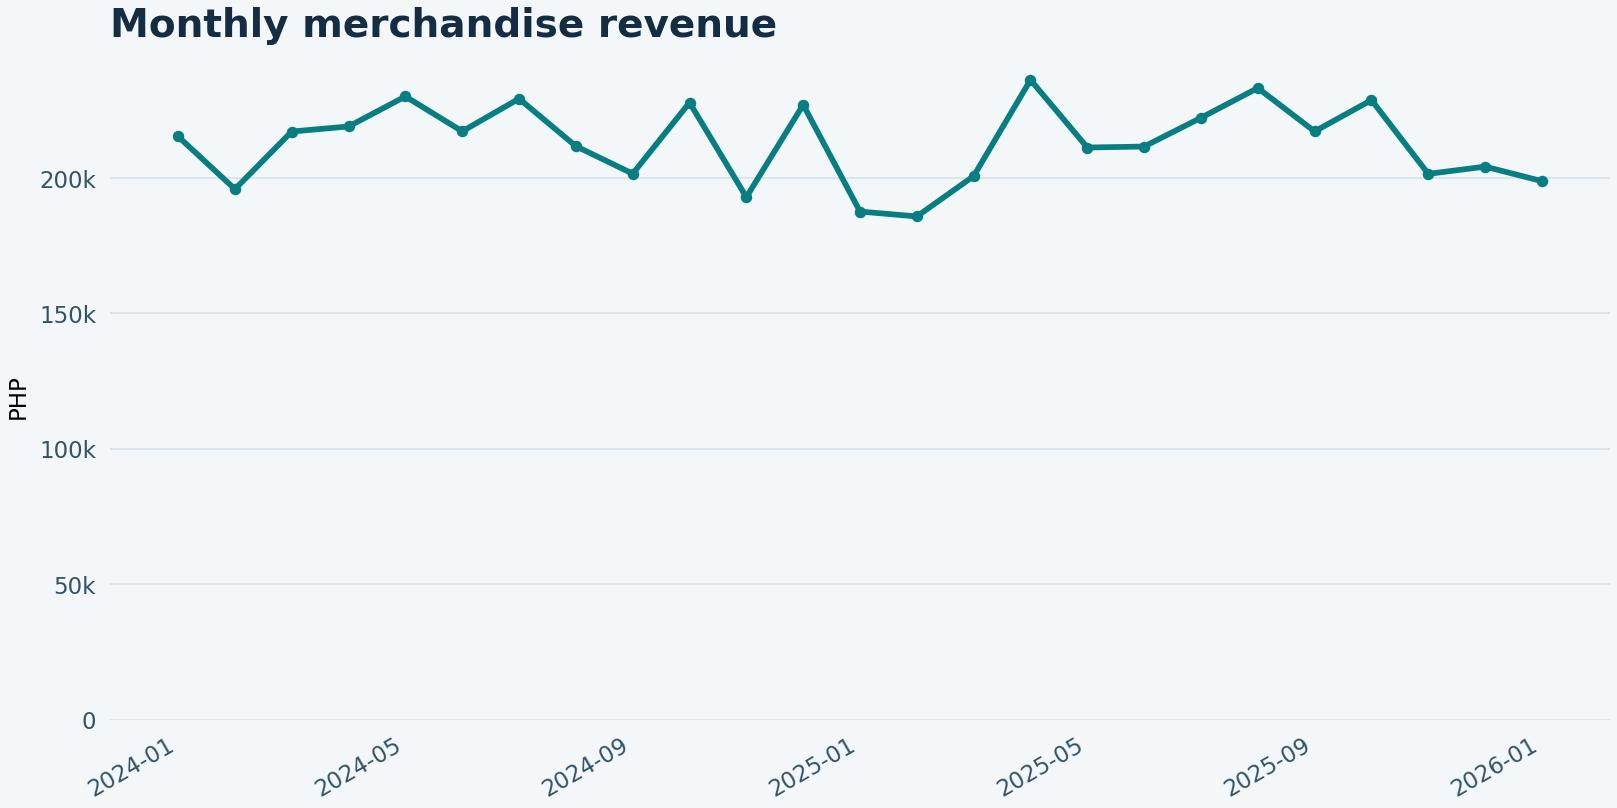

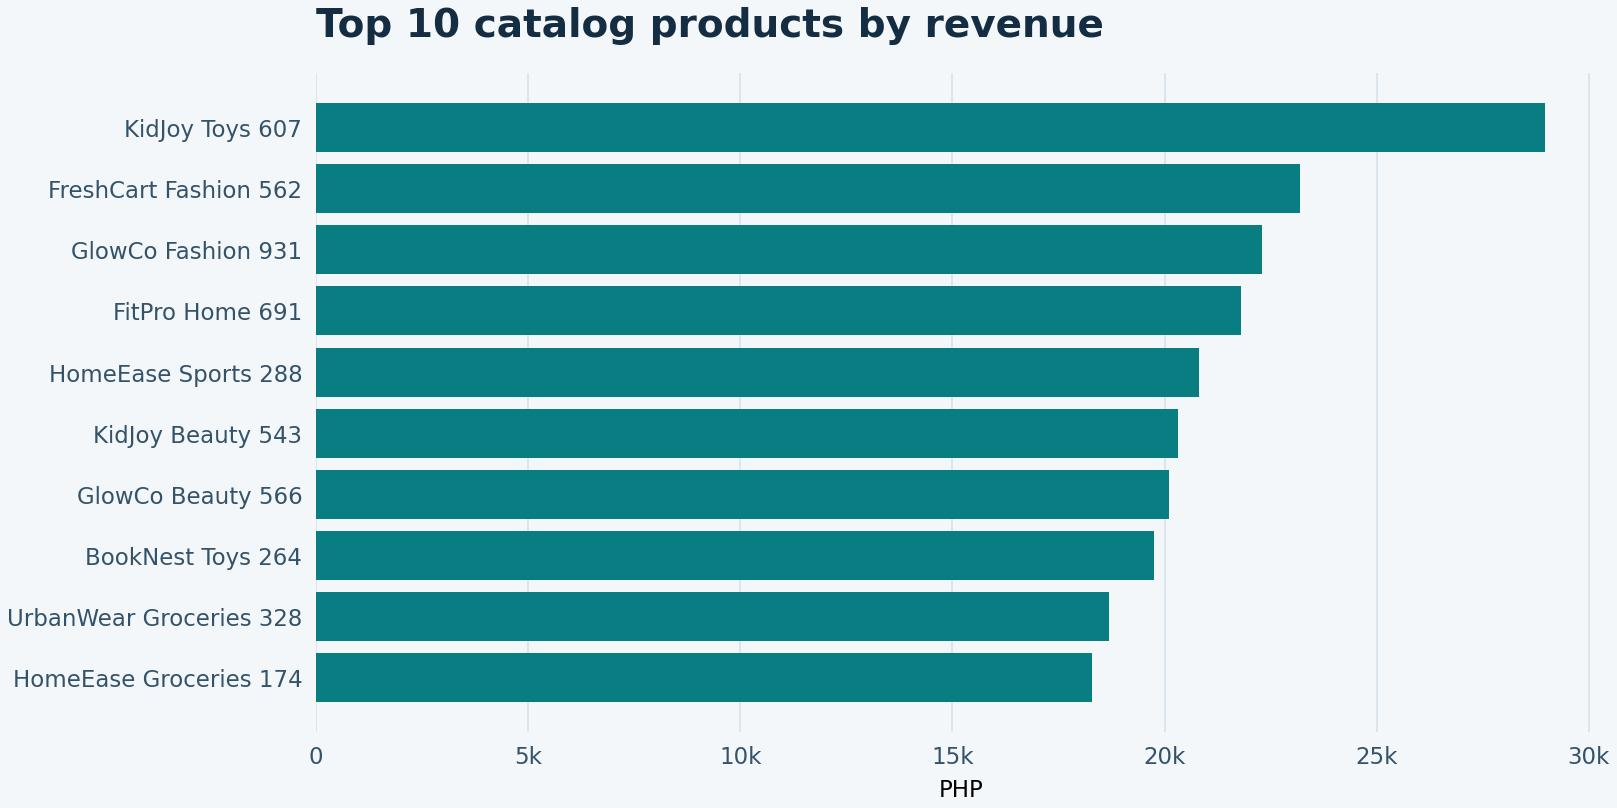

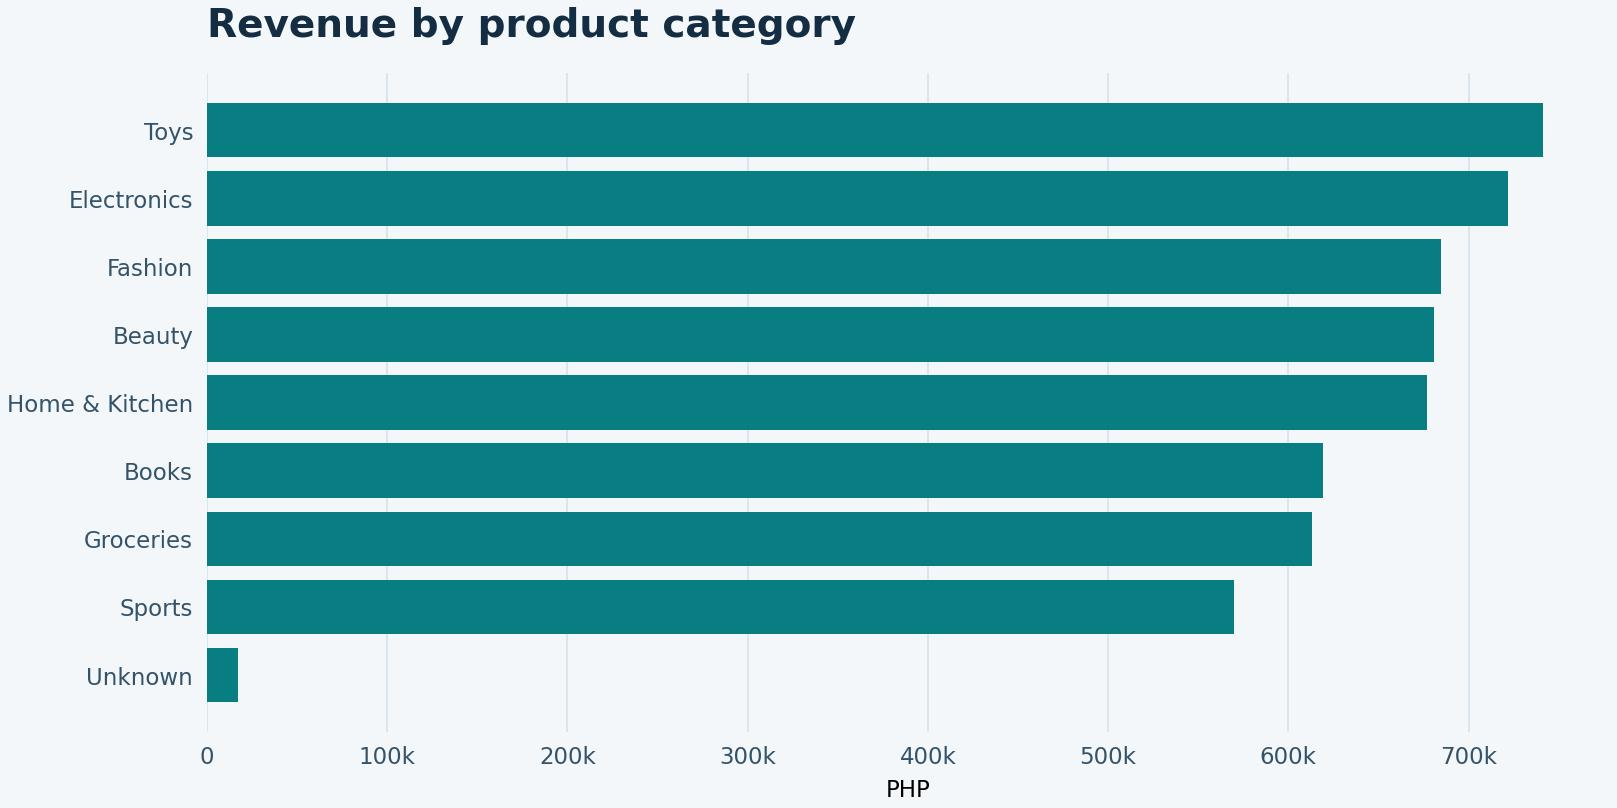

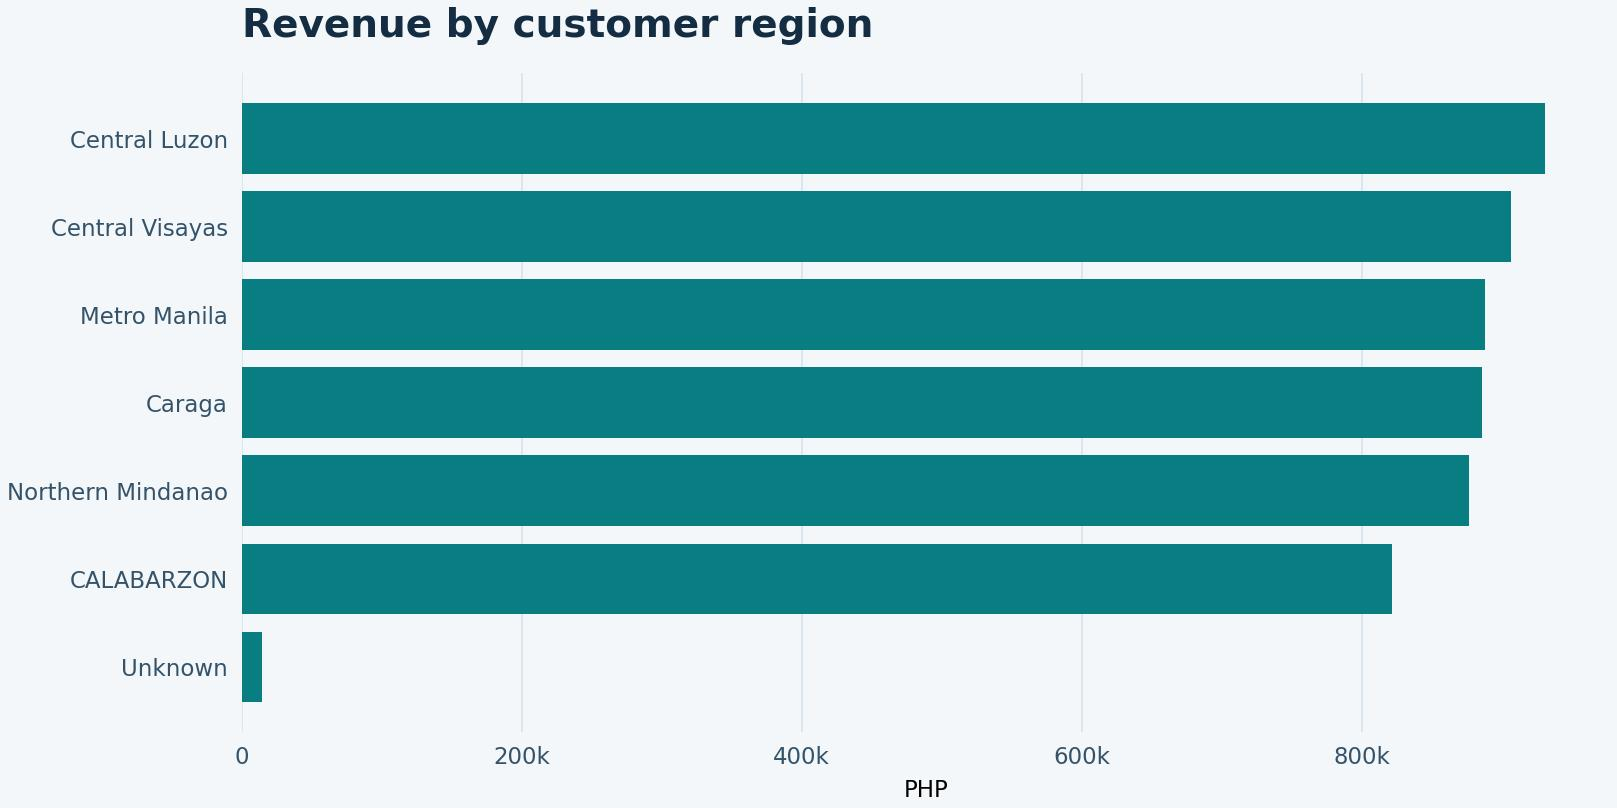

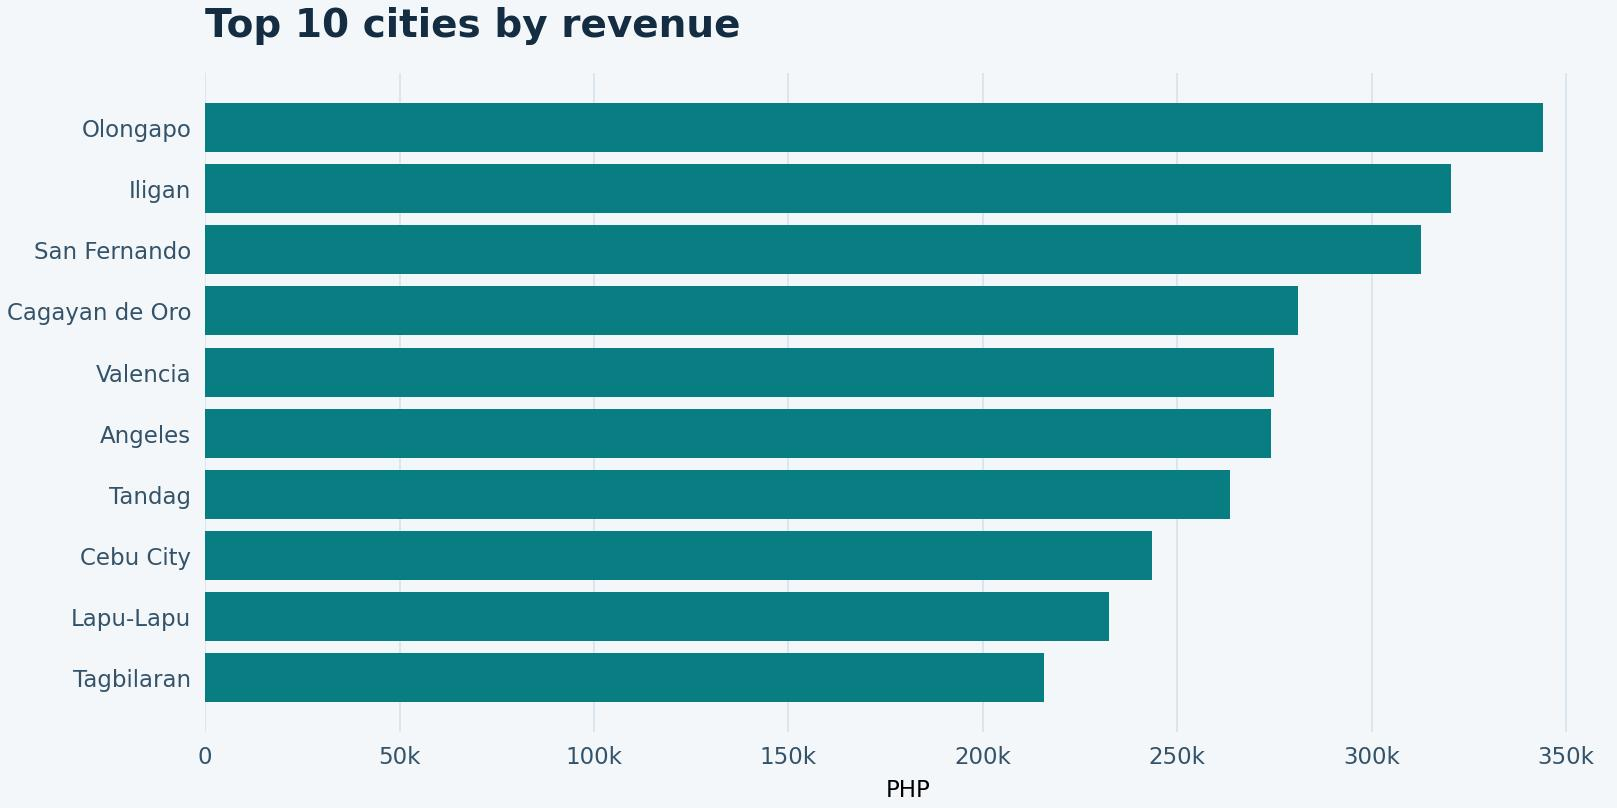

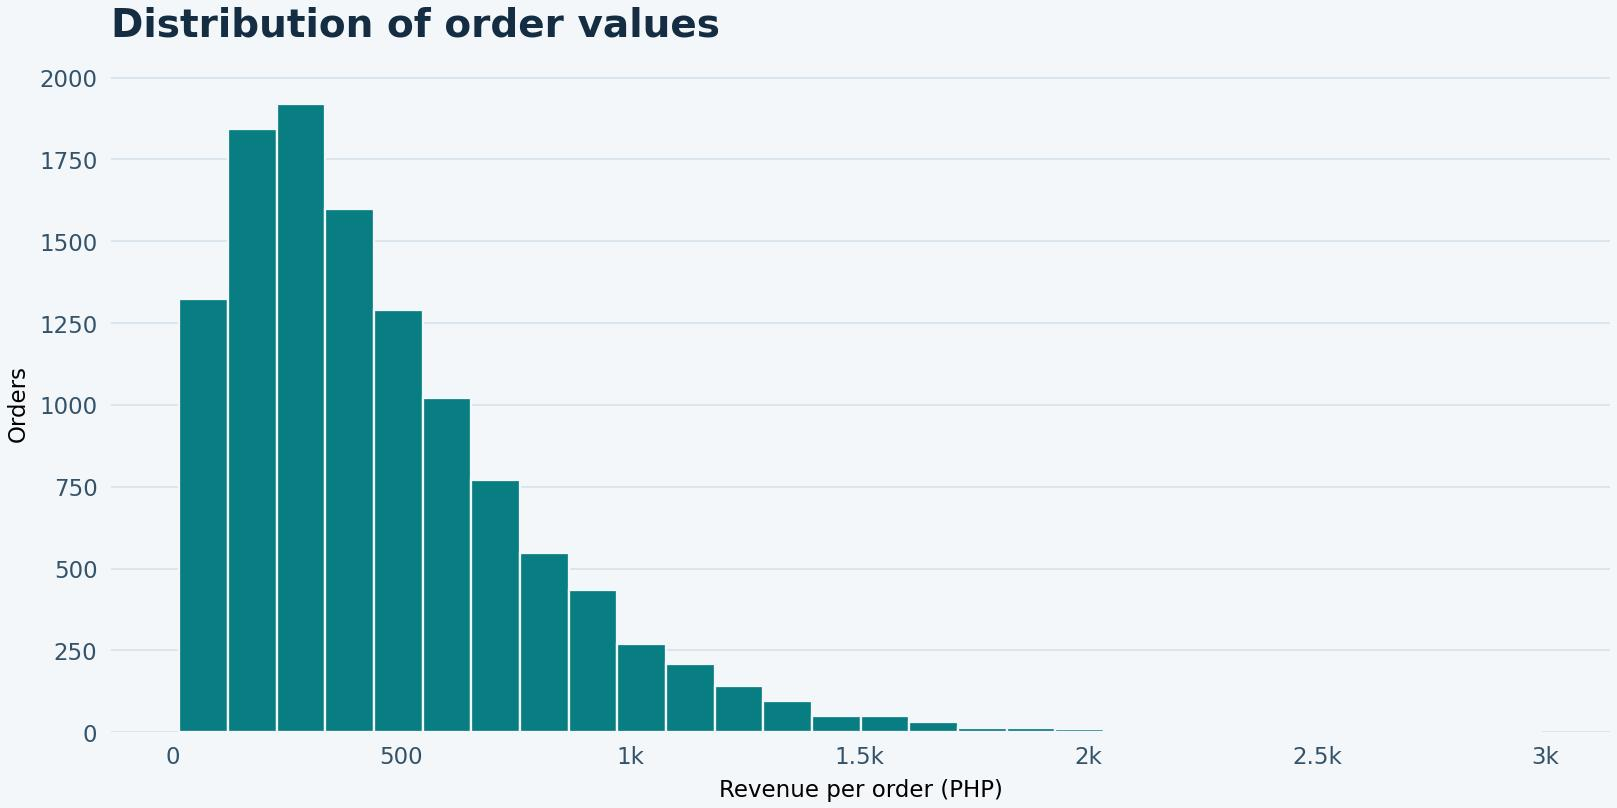

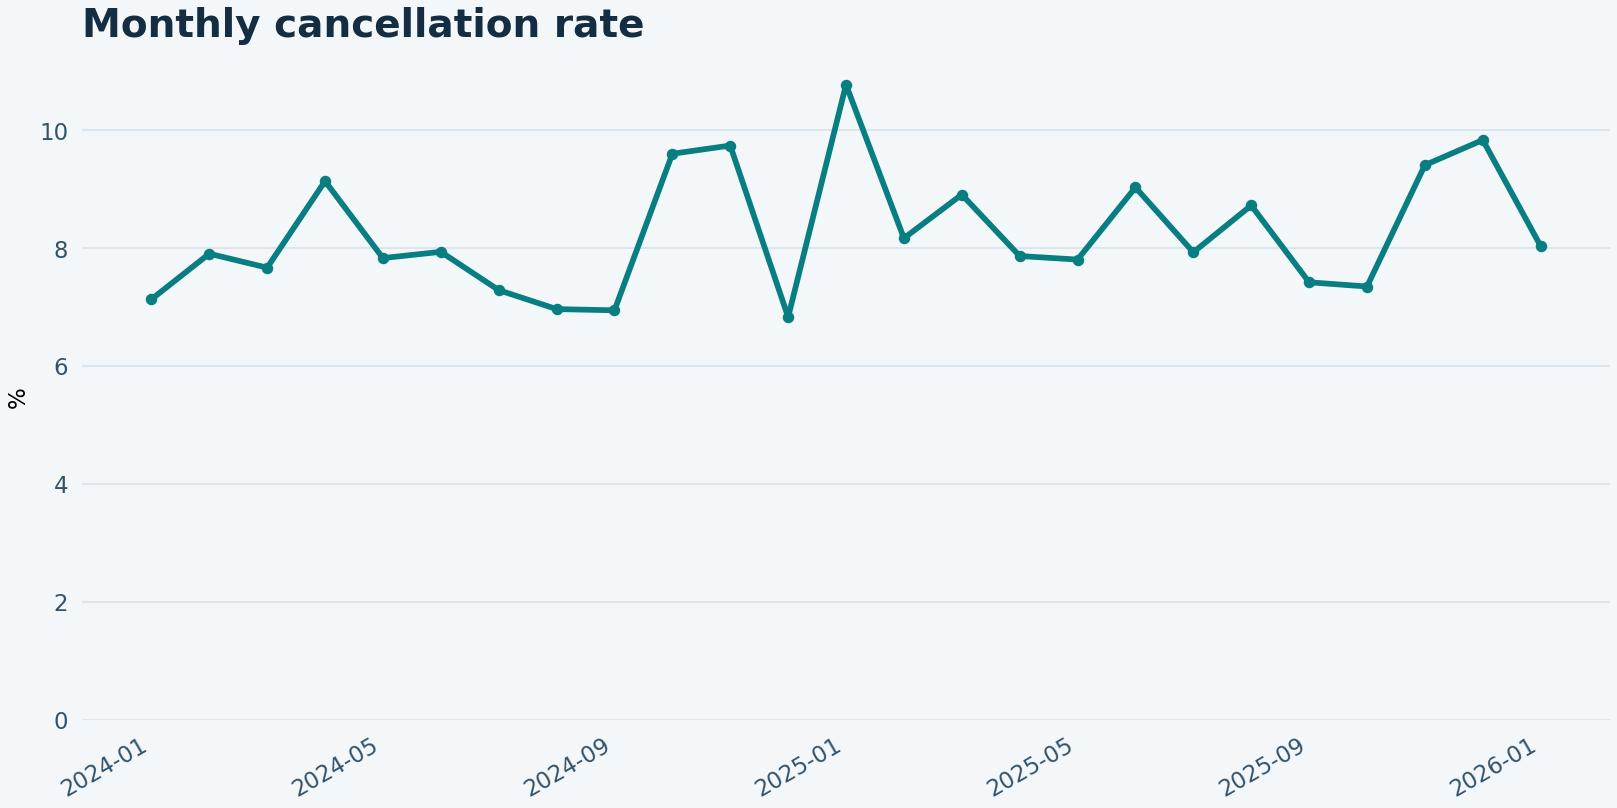

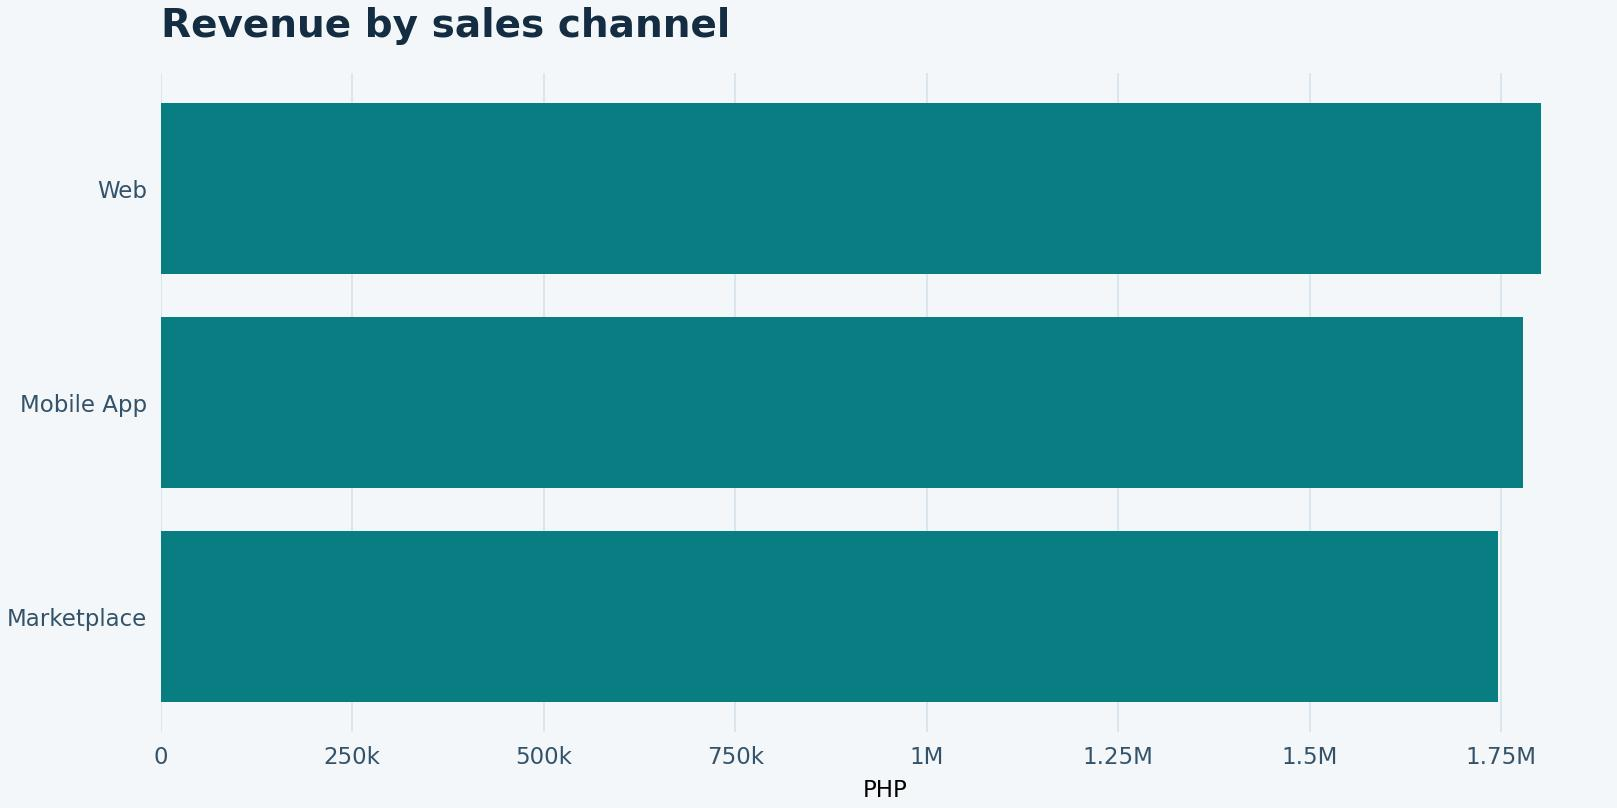

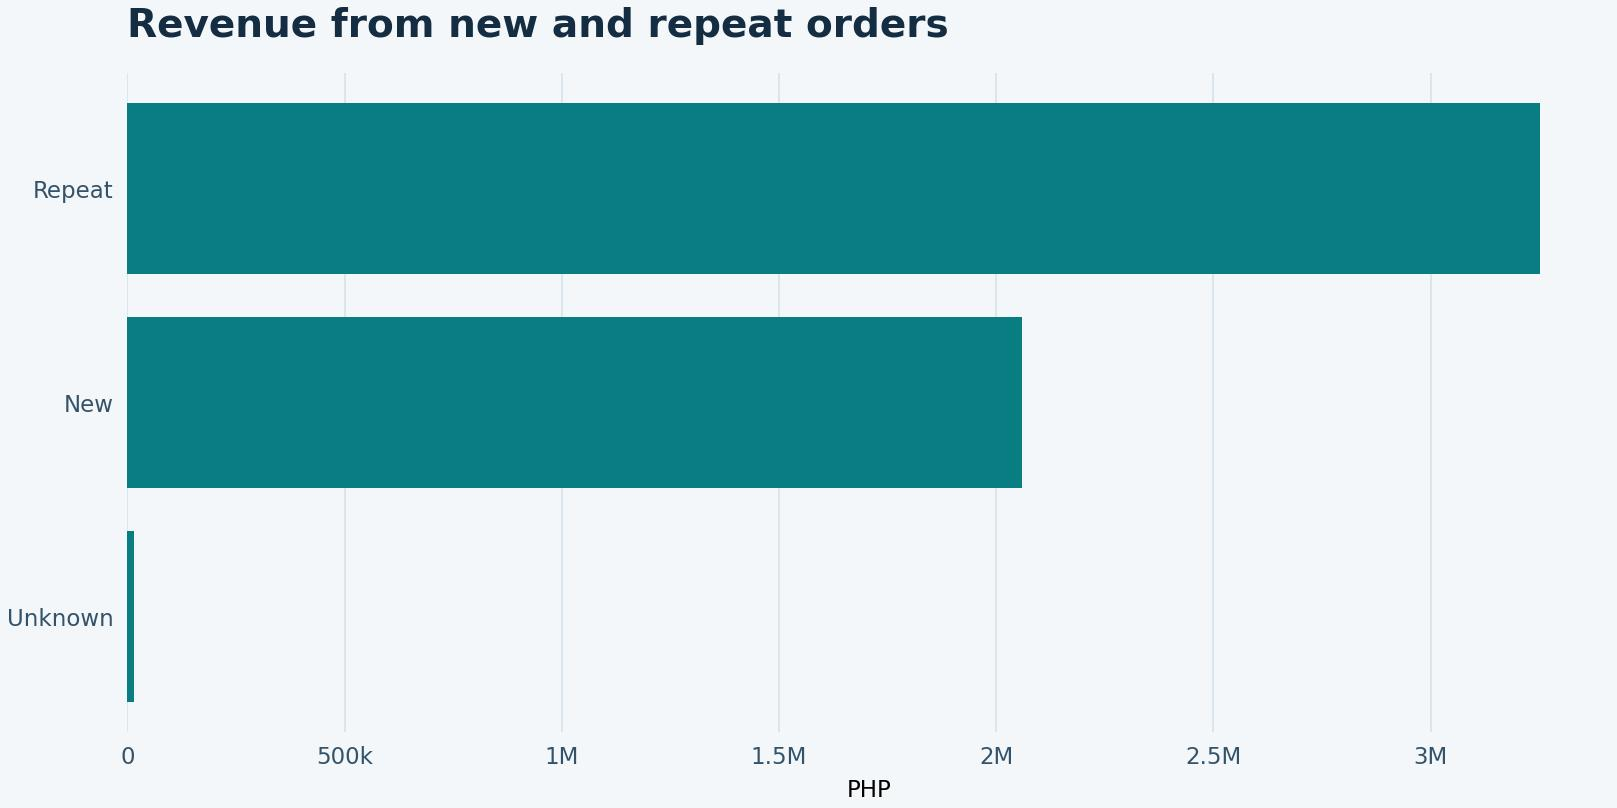

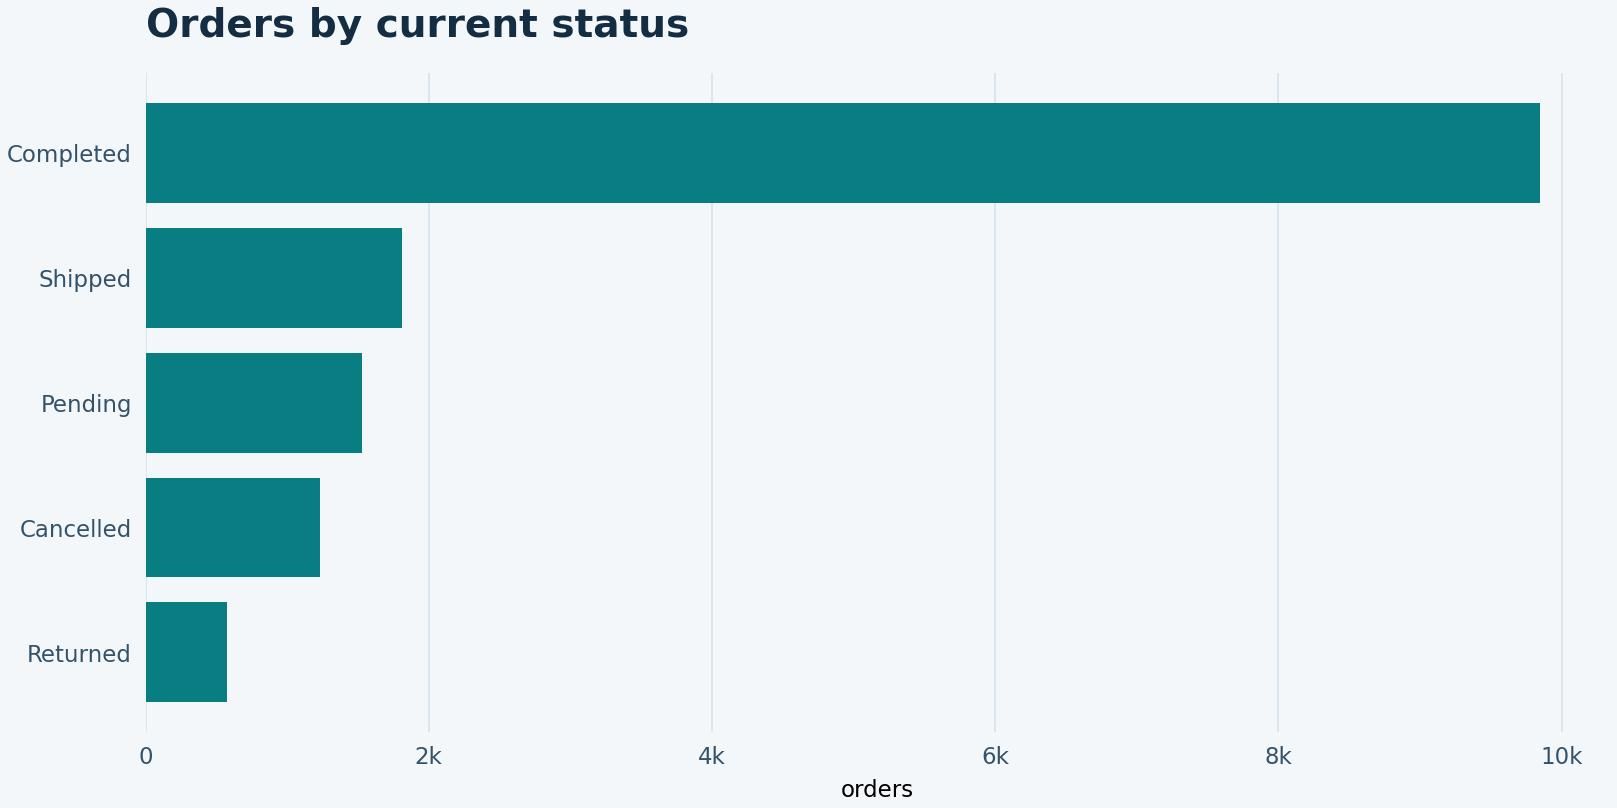

In [5]:
chart_folder = ROOT / "charts"
chart_folder.mkdir(exist_ok=True)
for number, spec in enumerate(CHARTS, start=1):
    destination = chart_folder / f"{number:02d}_{spec[0]}.jpg"
    fig = make_chart(metrics, spec)
    fig.savefig(destination, dpi=165, facecolor=fig.get_facecolor())
    plt.close(fig)
    display(Image(filename=str(destination), width=850))

## 5. Executive findings and recommendations

In [6]:
print((ROOT / "executive_summary.txt").read_text(encoding="utf-8"))

RETAIL SALES AND CUSTOMER INSIGHTS | JAN 2024–JAN 2026
- Estimated merchandise revenue was ₱5.33M across 11,643 revenue-bearing orders, with an average order value of ₱457.38.
- Revenue fell 1.7% from ₱2.59M in 2024 to ₱2.54M in 2025. April 2025 led all months at ₱236.3k.
- Toys led categories at ₱741.5k (13.9% of revenue), followed by Electronics at ₱721.9k. KidJoy Toys 607 led catalog products at ₱29.0k.
- Central Luzon led regions at ₱930.9k (17.5%). Olongapo led cities at ₱344.2k.
- Web led channels at ₱1.80M. Mobile App and Marketplace each generated about ₱1.75M–₱1.78M.
- Repeat orders generated ₱3.25M (61.0% of revenue) versus ₱2.06M from first observed orders. Unmatched customers accounted for the balance.
- Median order value was ₱379.51, below the ₱457.38 mean. The 90th percentile was ₱903.12.
- 1,235 of 15,000 orders were cancelled (8.2%). January 2025 had the highest order-month cancellation rate at 10.8%.
- Recommendation 1 — Test a second-purchase offer on a first-order c